# PathSnap: comparison of the five candidate-scoring models

Every number in this notebook is read from the files written by the five training runs (`../modelN/results.json`,
`fold_results.csv`, `per_trip_top1.csv`, `student_predictions.parquet`, `config.json`). Nothing is typed in by hand.
All five models were evaluated with the same code (`common/experiment.py`, `common/metrics.py`): the same 5 trip-grouped
CV folds on the 80 training trips, the same 22 features, the same fit rows (`fit_include == True`), and student-test
(10 trips) used for evaluation only.

**Partitions.** "CV" = out-of-fold predictions on the **train** partition (80 trips). "Student" = the **student_test**
partition (10 trips). The evaluator partition is never used.

## Metric definitions (same as `common/metrics.py`)

* **Top-1 (all points)**: per GPS point, the highest-scoring candidate is compared with the aligned label arc. Points
  whose label arc is not among the candidates count as misses. **Top-1 (label in candidates)** uses only the points
  whose label arc is a candidate.
* **Macro F1** (our own definition; the guidelines do not define it): candidate level, top-scoring candidate of each
  point = 1, all others = 0; mean of F1(class 1) and F1(class 0).
* **Log loss (raw)**: binary cross-entropy of raw candidate probabilities over all rows. **Log loss (normalised)**:
  probabilities normalised within each point (HMM emission view), mean of -log p(true arc) over points whose label is
  a candidate.
* **Candidate miss rate**: share of points whose label arc is not a candidate (identical for all models: ceiling on Top-1).
* **Route continuity**: share of consecutive top-1 arcs (GPS order, repeats collapsed) that connect in the trip's network.
* **ECE / Brier**: calibration of the raw probabilities.
* **Inference time**: model prediction only, per 1,000 GPS points, student partition, features already built.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sys
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "comparison" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
from common import plotting

FIG = ROOT / "comparison" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200, "display.max_columns", 40)

MODELS = {   # folder -> short label used in tables and plots
    "model1": "LogReg", "model2": "KNN", "model3": "RandomForest", "model4": "LightGBM", "model5": "MLP",
}
res = {m: json.loads((ROOT / m / "results.json").read_text()) for m in MODELS}
cfg = {m: json.loads((ROOT / m / "config.json").read_text()) for m in MODELS}
folds = pd.concat([pd.read_csv(ROOT / m / "fold_results.csv").assign(model=MODELS[m]) for m in MODELS], ignore_index=True)
print({MODELS[m]: r["seeds"] for m, r in res.items()})

{'LogReg': [42], 'KNN': [42], 'RandomForest': [42], 'LightGBM': [42], 'MLP': [42, 43, 44]}


## Key configuration of each model (from each `config.json`)

In [2]:
def key_config(m):
    h = cfg[m]["hyperparameters"]
    if m == "model1": return f"L2, C={h['C']}, lbfgs, class-weighted + sample weights, scaled table"
    if m == "model2": return f"k={h['n_neighbors']}, distance-weighted, euclidean, {h['subsample_rows']:,}-row subsample, no sample weights, scaled table"
    if m == "model3": return f"{h['n_estimators']} trees, max_depth={h['max_depth']}, min_leaf={h['min_samples_leaf']}, max_samples={h['max_samples']}, sqrt features, sample weights, raw table"
    if m == "model4": return f"lr={h['learning_rate']}, leaves={h['num_leaves']}, min_child={h['min_child_samples']}, early stop {h['early_stopping_rounds']} on 20% trips then refit, sample weights, raw table"
    if m == "model5": return f"22-{h['hidden_units']}-1 ReLU, dropout {h['dropout']}, Adam lr={h['learning_rate']}, batch {h['batch_size']}, early stop (patience {h['patience']}), 3 seeds, sample weights, scaled table"

def size_mb(m):
    files = [f for f in res[m]["saved_files"] if f not in ("scaler.joblib",) and not f.endswith(".json")]
    return round(sum((ROOT / m / f).stat().st_size for f in files) / 1e6, 2)

for m in MODELS: print(f"{MODELS[m]:13s} {key_config(m)}")

LogReg        L2, C=1.0, lbfgs, class-weighted + sample weights, scaled table
KNN           k=50, distance-weighted, euclidean, 150,000-row subsample, no sample weights, scaled table
RandomForest  100 trees, max_depth=12, min_leaf=100, max_samples=0.3, sqrt features, sample weights, raw table
LightGBM      lr=0.05, leaves=63, min_child=100, early stop 100 on 20% trips then refit, sample weights, raw table
MLP           22-64-1 ReLU, dropout 0.1, Adam lr=0.001, batch 4096, early stop (patience 5), 3 seeds, sample weights, scaled table


## Consolidated comparison table → `model_comparison.csv`

In [3]:
rows = []
for m, r in res.items():
    cv, st, tr = r["cv"]["all"], r["student"]["all"], r["train"]["all"]
    note = []
    if m == "model2":
        note.append("training time = storing a 150k-row subsample (lazy learner); cost moves to inference")
        note.append("sample weights N/A in sklearn KNN")
    if m == "model1":
        note.append("raw probabilities shifted by class weights (poor raw calibration by design)")
    if m == "model5":
        note.append("mean of 3 seeds; seed spread in model5/results.json seed_std")
    rows.append({
        "model": MODELS[m], "family": r["family"], "key_configuration": key_config(m),
        "cv_top1_all_mean": cv["top1_all"]["mean"], "cv_top1_all_std": cv["top1_all"]["std"],
        "cv_top1_in_cands_mean": cv["top1_in_cands"]["mean"], "cv_top1_in_cands_std": cv["top1_in_cands"]["std"],
        "cv_macro_f1_mean": cv["macro_f1"]["mean"], "cv_macro_f1_std": cv["macro_f1"]["std"],
        "cv_logloss_raw_mean": cv["logloss_raw"]["mean"], "cv_logloss_norm_mean": cv["logloss_norm"]["mean"],
        "cv_clean_top1_all_mean": r["cv"]["clean"]["top1_all"]["mean"],
        "train_top1_all": tr["top1_all"],
        "route_continuity_cv": r["route_continuity"]["cv_oof"]["pooled"],
        "route_continuity_student": r["route_continuity"]["student"]["pooled"],
        "student_top1_all": st["top1_all"], "student_top1_in_cands": st["top1_in_cands"],
        "student_macro_f1": st["macro_f1"],
        "student_logloss_raw": st["logloss_raw"], "student_logloss_norm": st["logloss_norm"],
        "student_clean_top1_all": r["student"]["clean"]["top1_all"],
        "student_ece": st["ece"], "student_brier": st["brier"],
        "cv_accuracy_mean": cv["accuracy"]["mean"], "cv_precision_1_mean": cv["precision_1"]["mean"],
        "cv_recall_1_mean": cv["recall_1"]["mean"], "cv_f1_1_mean": cv["f1_1"]["mean"], "cv_f1_0_mean": cv["f1_0"]["mean"],
        "student_accuracy": st["accuracy"], "student_precision_1": st["precision_1"], "student_recall_1": st["recall_1"],
        "student_f1_1": st["f1_1"], "student_precision_0": st["precision_0"], "student_recall_0": st["recall_0"],
        "student_f1_0": st["f1_0"],
        "student_seq_precision": r["sequence_level"]["student"]["seq_precision"],
        "student_seq_recall": r["sequence_level"]["student"]["seq_recall"],
        "student_seq_f1": r["sequence_level"]["student"]["seq_f1"],
        "student_seq_f1_trip_mean": r["sequence_level"]["student"]["seq_f1_trip_mean"],
        "student_pred_to_ref_length_ratio": r["sequence_level"]["student"]["pred_to_ref_length_ratio"],
        "cv_seq_f1": (r["sequence_level"]["cv_oof"]["seq_f1"] if isinstance(r["sequence_level"]["cv_oof"], dict)
                      else "N/A: first-run out-of-fold predictions not saved"),
        "cv_training_seconds_total": float(sum(r["timing"]["cv_fit_seconds_per_fold"])),
        "candidate_miss_rate_train": r["candidate_miss_rate"]["train"], "candidate_miss_rate_student": r["candidate_miss_rate"]["student"],
        "final_fit_seconds": r["timing"]["final_fit_seconds"],
        "inference_ms_per_1000_points": r["timing"]["inference_ms_per_1000_points"],
        "model_file_mb": size_mb(m),
        "notes": "; ".join(note) if note else "",
    })
comp = pd.DataFrame(rows)
comp.to_csv(ROOT / "comparison" / "model_comparison.csv", index=False)
show = ["model", "cv_top1_all_mean", "cv_top1_all_std", "cv_top1_in_cands_mean", "cv_macro_f1_mean", "cv_logloss_norm_mean",
        "route_continuity_cv", "student_top1_all", "student_macro_f1", "student_logloss_raw", "student_logloss_norm",
        "student_ece", "final_fit_seconds", "inference_ms_per_1000_points", "model_file_mb"]
comp[show].round(4)

,model,cv_top1_all_mean,cv_top1_all_std,cv_top1_in_cands_mean,cv_macro_f1_mean,cv_logloss_norm_mean,route_continuity_cv,student_top1_all,student_macro_f1,student_logloss_raw,student_logloss_norm,student_ece,final_fit_seconds,inference_ms_per_1000_points,model_file_mb
0,LogReg,0.7584,0.1269,0.8347,0.8839,0.7790,0.7119,0.8326,0.9081,0.1835,0.7357,0.0849,2.79,0.1980,0.00
1,KNN,0.7582,0.1258,0.8346,0.8838,1.1738,0.7057,0.8428,0.9138,0.1141,0.7614,0.0039,0.11,1072.3280,7.50
2,RandomForest,0.7652,0.1264,0.8426,0.8879,0.5024,0.7126,0.8447,0.9148,0.0739,0.4462,0.0117,27.71,20.0630,4.43
3,LightGBM,0.7733,0.1291,0.8514,0.8926,0.4461,0.7285,0.8636,0.9252,0.0679,0.4018,0.0057,16.29,9.4640,0.55
4,MLP,0.7734,0.1286,0.8515,0.8927,0.4784,0.7305,0.8593,0.9229,0.0701,0.4076,0.0015,71.71,3.5217,0.03


## Applying the selection rule (primary CV Top-1 on all points, tie-breaker normalised log loss)

What counts as a tie: a CV Top-1 difference smaller than the **seed-to-seed spread** we measured (the std of the
MLP's CV Top-1 over its 3 seeds). A difference that small can come from re-running the same model with another seed,
so it cannot rank two models. Tied models are then ranked by CV log loss (normalised per point, the HMM view).

In [4]:
TIE_TOL = res["model5"]["seed_std"]["cv"]["all"]["top1_all"]["mean"]   # measured, not chosen by hand
top = comp["cv_top1_all_mean"].max()
tied = comp[comp["cv_top1_all_mean"] >= top - TIE_TOL]
best = tied.sort_values("cv_logloss_norm_mean").iloc[0]["model"]
print(f"tie tolerance (MLP seed std of CV Top-1): {TIE_TOL:.5f}")
print("models tied on CV Top-1:", tied["model"].tolist())
display(tied[["model", "cv_top1_all_mean", "cv_logloss_norm_mean", "student_top1_all", "student_logloss_norm"]].round(5))
print("MLP per seed (CV Top-1, CV normalised log loss):",
      {s: (round(v["cv"]["all"]["top1_all"]["mean"], 5), round(v["cv"]["all"]["logloss_norm"]["mean"], 4)) for s, v in res["model5"]["per_seed"].items()})
print(f"Selected by the rule: {best}")

tie tolerance (MLP seed std of CV Top-1): 0.00061
models tied on CV Top-1: ['LightGBM', 'MLP']


,model,cv_top1_all_mean,cv_logloss_norm_mean,student_top1_all,student_logloss_norm
3,LightGBM,0.77329,0.44606,0.86357,0.40177
4,MLP,0.77343,0.47838,0.85934,0.40757


MLP per seed (CV Top-1, CV normalised log loss): {'42': (0.77318, 0.4767), '43': (0.77284, 0.479), '44': (0.77426, 0.4794)}
Selected by the rule: LightGBM


## Fold-by-fold Top-1 (all points): stability and paired differences

The fold standard deviation is large for every model because folds differ in how many far / uncovered points they hold
(the same trips are in the same fold for every model). Because all models share the folds, the **paired per-fold
difference** to the best model is the fairer stability check.

In [5]:
ft = folds[(folds.subset == "all")].groupby(["model", "fold"])["top1_all"].mean().unstack("fold")
ft = ft.loc[[MODELS[m] for m in MODELS]]
diff = ft.sub(ft.loc[best], axis=1)
diff["mean_diff"] = diff.mean(axis=1); diff["folds_worse"] = (diff.drop(columns="mean_diff") < 0).sum(axis=1)
print("Top-1 (all) per fold:"); display(ft.round(4))
print(f"Paired difference to {best} (negative = worse than {best}):"); display(diff.round(4))
fig, ax = plt.subplots(figsize=(7, 4))
for mdl, row in ft.iterrows(): ax.plot(row.index, row.values, marker="o", label=mdl)
ax.set_xlabel("CV fold (train partition)"); ax.set_ylabel("Top-1 (all points)"); ax.set_xticks(ft.columns)
ax.set_title("Top-1 per CV fold, all five models"); ax.legend(fontsize=8); fig.tight_layout()
fig.savefig(FIG / "cv_top1_per_fold.png", dpi=130); plt.show()

Top-1 (all) per fold:


fold,0,1,2,3,4
model,,,,,
LogReg,0.8210,0.8746,0.5439,0.7623,0.7903
KNN,0.8185,0.8739,0.5454,0.7637,0.7893
RandomForest,0.8226,0.8895,0.5546,0.7650,0.7941
LightGBM,0.8185,0.9066,0.5597,0.7740,0.8077
MLP,0.8350,0.8978,0.5591,0.7724,0.8027


Paired difference to LightGBM (negative = worse than LightGBM):


fold,0,1,2,3,4,mean_diff,folds_worse
model,,,,,,,
LogReg,0.0025,-0.0320,-0.0158,-0.0117,-0.0174,-0.0149,4
KNN,0.0001,-0.0328,-0.0143,-0.0103,-0.0184,-0.0151,4
RandomForest,0.0041,-0.0171,-0.0051,-0.0090,-0.0136,-0.0081,4
LightGBM,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0
MLP,0.0165,-0.0088,-0.0006,-0.0016,-0.0049,0.0001,4


C:\Users\shiva\AppData\Local\Temp\ipykernel_30044\1297895090.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.savefig(FIG / "cv_top1_per_fold.png", dpi=130); plt.show()


## Comparison plots (all from the results files)

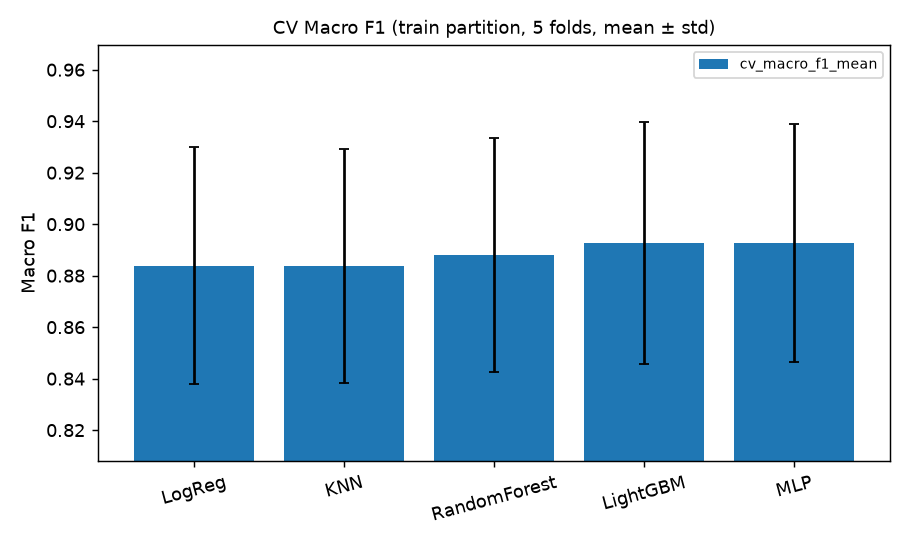

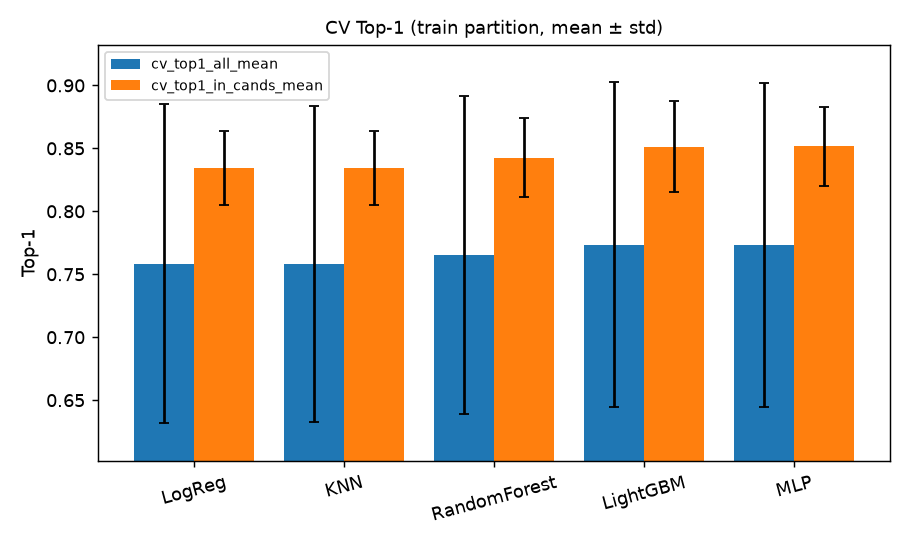

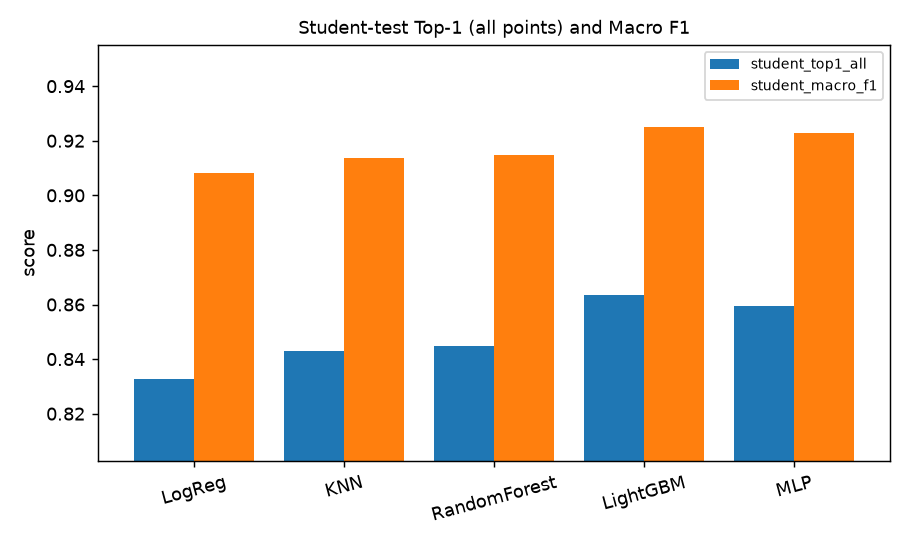

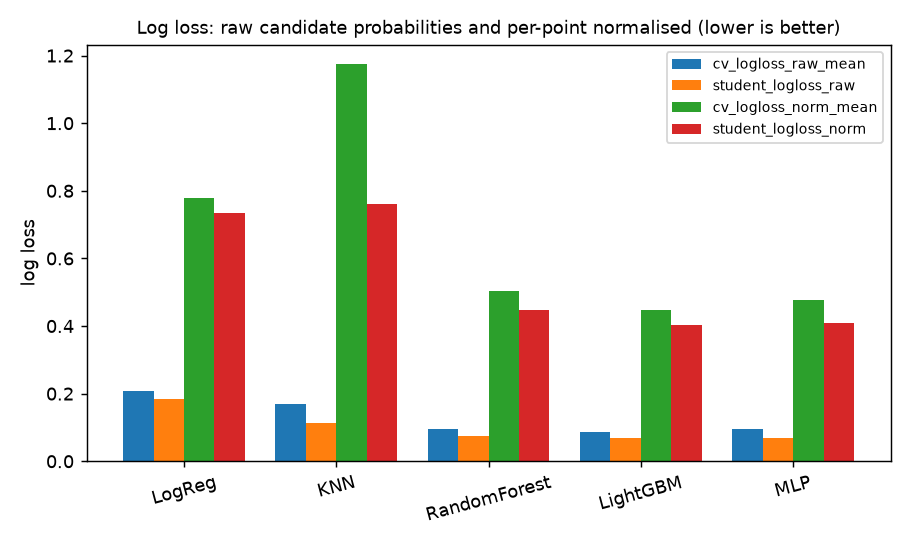

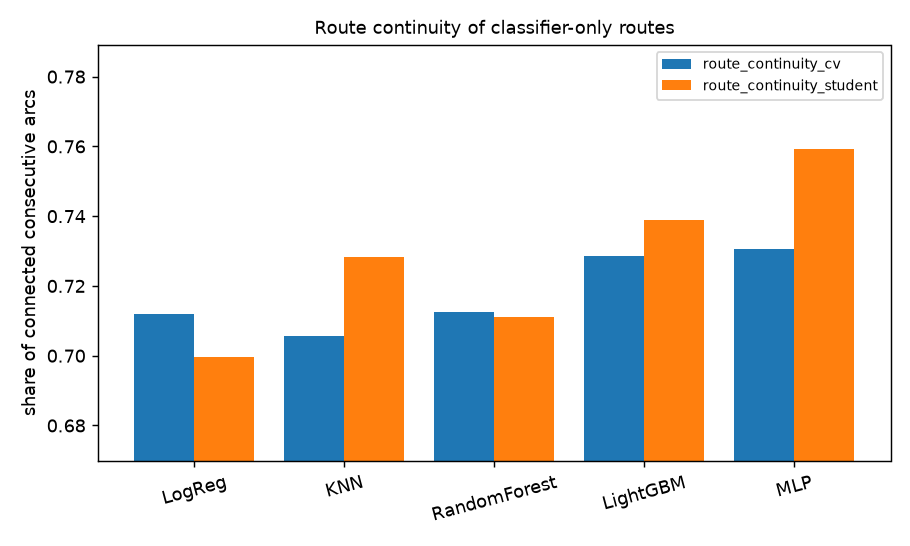

In [6]:
plotting.plot_model_bars(comp, ["cv_macro_f1_mean"], "CV Macro F1 (train partition, 5 folds, mean ± std)", "Macro F1",
                         FIG / "cv_macro_f1.png", err={"cv_macro_f1_mean": "cv_macro_f1_std"})
plotting.plot_model_bars(comp, ["cv_top1_all_mean", "cv_top1_in_cands_mean"], "CV Top-1 (train partition, mean ± std)", "Top-1",
                         FIG / "cv_top1.png", err={"cv_top1_all_mean": "cv_top1_all_std", "cv_top1_in_cands_mean": "cv_top1_in_cands_std"})
plotting.plot_model_bars(comp, ["student_top1_all", "student_macro_f1"], "Student-test Top-1 (all points) and Macro F1", "score",
                         FIG / "student_top1_macro_f1.png")
plotting.plot_model_bars(comp, ["cv_logloss_raw_mean", "student_logloss_raw", "cv_logloss_norm_mean", "student_logloss_norm"],
                         "Log loss: raw candidate probabilities and per-point normalised (lower is better)", "log loss",
                         FIG / "log_loss.png")
plotting.plot_model_bars(comp, ["route_continuity_cv", "route_continuity_student"], "Route continuity of classifier-only routes",
                         "share of connected consecutive arcs", FIG / "route_continuity.png")
for f in ["cv_macro_f1", "cv_top1", "student_top1_macro_f1", "log_loss", "route_continuity"]:
    display(__import__("IPython").display.Image(str(FIG / f"{f}.png")))

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(comp["model"], comp["inference_ms_per_1000_points"])
ax.set_yscale("log"); ax.set_ylabel("ms per 1,000 GPS points (log scale)")
ax.set_title("Inference time (student partition, model prediction only)"); fig.tight_layout()
fig.savefig(FIG / "inference_time.png", dpi=130); plt.show()

C:\Users\shiva\AppData\Local\Temp\ipykernel_30044\3956436619.py:5: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.savefig(FIG / "inference_time.png", dpi=130); plt.show()


## Train vs CV vs student (over- / under-fitting evidence)

In [8]:
gap = comp[["model", "train_top1_all", "cv_top1_all_mean", "student_top1_all"]].copy()
gap["train_minus_cv"] = gap.train_top1_all - gap.cv_top1_all_mean
gap["cv_minus_student"] = gap.cv_top1_all_mean - gap.student_top1_all
display(gap.round(4))
x = np.arange(len(gap)); w = 0.27
fig, ax = plt.subplots(figsize=(8, 4))
for i, c in enumerate(["train_top1_all", "cv_top1_all_mean", "student_top1_all"]):
    ax.bar(x + (i - 1) * w, gap[c], w, label=c)
ax.set_xticks(x, gap.model); ax.set_ylim(0.6, 1.0); ax.set_ylabel("Top-1 (all points)")
ax.set_title("Train (refit, in-sample) vs CV (out-of-fold) vs student-test"); ax.legend(fontsize=8); fig.tight_layout()
fig.savefig(FIG / "train_cv_student_gap.png", dpi=130); plt.show()

,model,train_top1_all,cv_top1_all_mean,student_top1_all,train_minus_cv,cv_minus_student
0,LogReg,0.7528,0.7584,0.8326,-0.0056,-0.0741
1,KNN,0.7947,0.7582,0.8428,0.0366,-0.0846
2,RandomForest,0.7759,0.7652,0.8447,0.0107,-0.0796
3,LightGBM,0.7971,0.7733,0.8636,0.0239,-0.0903
4,MLP,0.7809,0.7734,0.8593,0.0075,-0.0859


C:\Users\shiva\AppData\Local\Temp\ipykernel_30044\3015694764.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.savefig(FIG / "train_cv_student_gap.png", dpi=130); plt.show()


## Confusion matrices (student-test, candidate level at the top-1 decision; optional diagnostic)

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.6))
for ax, m in zip(axes, MODELS):
    cm = np.asarray(res[m]["confusion_matrix"]["student_all"])
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm): ax.text(j, i, f"{int(round(v)):,}", ha="center", va="center", fontsize=8)
    ax.set_xticks([0, 1], ["pred 0", "pred 1"]); ax.set_yticks([0, 1], ["true 0", "true 1"]); ax.set_title(MODELS[m], fontsize=9)
fig.suptitle("Student-test confusion matrices (rows = truth, columns = top-1 decision)", fontsize=10); fig.tight_layout()
fig.savefig(FIG / "confusion_matrices_student.png", dpi=130); plt.show()

C:\Users\shiva\AppData\Local\Temp\ipykernel_30044\1244245149.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.savefig(FIG / "confusion_matrices_student.png", dpi=130); plt.show()


## Accuracy, precision, recall, F1 per class (candidate level, top-1 decision)

Accuracy is dominated by the ~90% negative candidates (always predicting "not this road" already scores about 0.9),
so it says little here. Because every point gets exactly one predicted "1": precision of class 1 = Top-1 on all points,
and recall of class 1 = Top-1 on points whose label is a candidate. They are listed under their own names because the
guidelines ask for them.

,model,cv_accuracy_mean,cv_precision_1_mean,cv_recall_1_mean,cv_f1_1_mean,cv_f1_0_mean,student_accuracy,student_precision_1,student_recall_1,student_f1_1,student_precision_0,student_recall_0,student_f1_0
0,LogReg,0.9585,0.7584,0.8347,0.7908,0.9770,0.9693,0.8326,0.8338,0.8332,0.9831,0.9830,0.9831
1,KNN,0.9585,0.7582,0.8346,0.7906,0.9769,0.9711,0.8428,0.8441,0.8434,0.9842,0.9840,0.9841
2,RandomForest,0.9601,0.7652,0.8426,0.7980,0.9778,0.9715,0.8447,0.8460,0.8454,0.9844,0.9842,0.9843
3,LightGBM,0.9618,0.7733,0.8514,0.8065,0.9788,0.9750,0.8636,0.8649,0.8642,0.9863,0.9861,0.9862
4,MLP,0.9618,0.7734,0.8515,0.8066,0.9788,0.9742,0.8593,0.8606,0.8600,0.9859,0.9857,0.9858


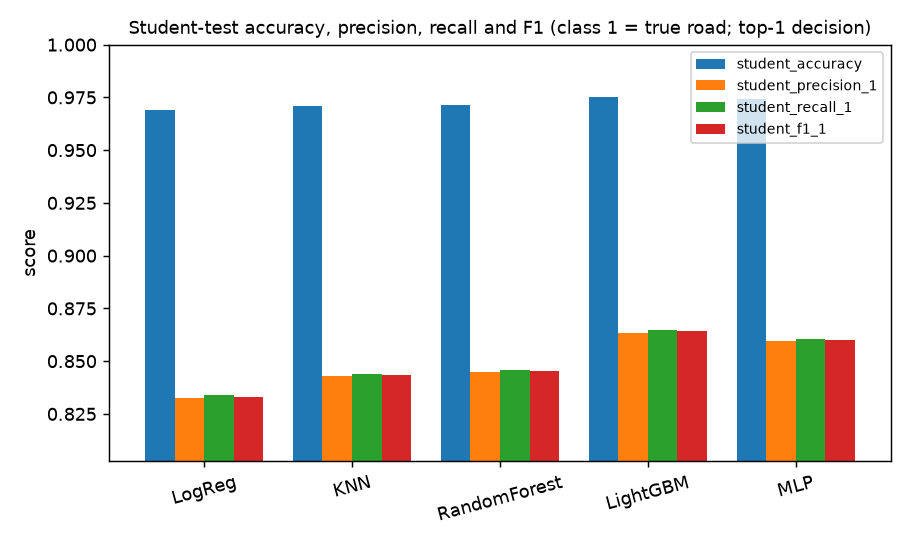

In [10]:
cls = comp[["model", "cv_accuracy_mean", "cv_precision_1_mean", "cv_recall_1_mean", "cv_f1_1_mean", "cv_f1_0_mean",
             "student_accuracy", "student_precision_1", "student_recall_1", "student_f1_1", "student_precision_0",
             "student_recall_0", "student_f1_0"]]
display(cls.round(4))
plotting.plot_model_bars(comp, ["student_accuracy", "student_precision_1", "student_recall_1", "student_f1_1"],
                         "Student-test accuracy, precision, recall and F1 (class 1 = true road; top-1 decision)", "score",
                         FIG / "student_precision_recall.png")
display(__import__("IPython").display.Image(str(FIG / "student_precision_recall.png")))

## Sequence-level performance (student-test, classifier-only routes)

Per trip, the predicted road sequence (top-1 arc per point, repeats collapsed) is compared with the reference sequence
(aligned label arc per point, repeats collapsed) by their longest common subsequence (LCS):
precision = LCS / predicted length, recall = LCS / reference length, F1 = 2 LCS / (sum of lengths).
Partition: **student_test only** for the first run (its out-of-fold train predictions were not saved, so CV sequence
metrics are N/A; future runs of the harness compute them).

,model,student_seq_precision,student_seq_recall,student_seq_f1,student_seq_f1_trip_mean,student_pred_to_ref_length_ratio,route_continuity_student
0,LogReg,0.5656,0.8738,0.6867,0.7121,1.5448,0.6997
1,KNN,0.5892,0.8973,0.7114,0.7455,1.5228,0.7283
2,RandomForest,0.5608,0.8857,0.6867,0.7155,1.5793,0.7112
3,LightGBM,0.5896,0.8988,0.7121,0.7385,1.5243,0.7389
4,MLP,0.5971,0.8956,0.7165,0.7416,1.5000,0.7592


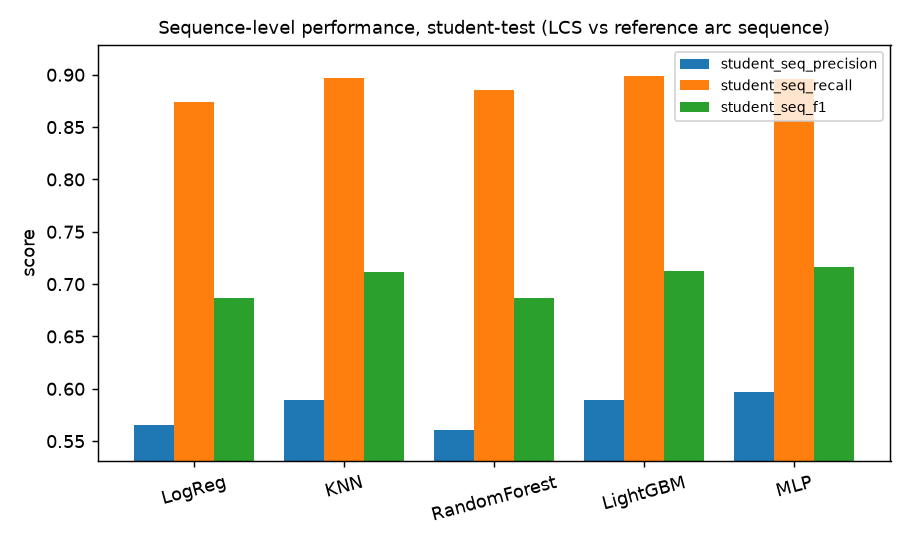

In [11]:
seq = comp[["model", "student_seq_precision", "student_seq_recall", "student_seq_f1", "student_seq_f1_trip_mean",
             "student_pred_to_ref_length_ratio", "route_continuity_student"]]
display(seq.round(4))
plotting.plot_model_bars(comp, ["student_seq_precision", "student_seq_recall", "student_seq_f1"],
                         "Sequence-level performance, student-test (LCS vs reference arc sequence)", "score",
                         FIG / "sequence_level_student.png")
display(__import__("IPython").display.Image(str(FIG / "sequence_level_student.png")))

## Calibration (raw candidate probabilities)

In [12]:
display(comp[["model", "student_ece", "student_brier", "student_logloss_raw", "student_logloss_norm"]].round(4))
cal = {MODELS[m]: res[m]["cv_oof_pooled"]["all"]["ece"] for m in MODELS}
print("CV out-of-fold ECE:", {k: round(v, 4) for k, v in cal.items()})

,model,student_ece,student_brier,student_logloss_raw,student_logloss_norm
0,LogReg,0.0849,0.0583,0.1835,0.7357
1,KNN,0.0039,0.0235,0.1141,0.7614
2,RandomForest,0.0117,0.0205,0.0739,0.4462
3,LightGBM,0.0057,0.0190,0.0679,0.4018
4,MLP,0.0015,0.0201,0.0701,0.4076


CV out-of-fold ECE: {'LogReg': 0.093, 'KNN': 0.0072, 'RandomForest': 0.0163, 'LightGBM': 0.0076, 'MLP': 0.0083}


## Per-trip Top-1 of the best model (weak trips)

In [13]:
best_folder = [m for m, lab in MODELS.items() if lab == best][0]
pt = pd.read_csv(ROOT / best_folder / "per_trip_top1.csv", dtype={"trip_id": str})
if "seed" in pt: pt = pt.groupby(["partition", "trip_id"], as_index=False).mean(numeric_only=True)
pt["weak_trip"] = pt["top1_all"] < 0.80
FAR_HEAVY = ["00000054", "00000033", "00000002"]   # far-heavy trips named in the preprocessing report
cols = ["partition", "trip_id", "n_points", "top1_all", "top1_in_cands", "miss_rate", "far_share", "route_continuity"]
print(f"Selected model: {best}")
print("Weak trips (Top-1 all < 0.80):"); display(pt[pt.weak_trip][cols].sort_values(["partition", "top1_all"]).round(3))
print("Far-heavy trips from the preprocessing report:"); display(pt[pt.trip_id.isin(FAR_HEAVY)][cols].round(3))
print("Student trips:"); display(pt[pt.partition == "student"][cols].sort_values("top1_all").round(3))

Selected model: LightGBM
Weak trips (Top-1 all < 0.80):


,partition,trip_id,n_points,top1_all,top1_in_cands,miss_rate,far_share,route_continuity
8,student,00000077,3911.0,0.763,0.763,0.000,0.003,0.744
54,train_cv_oof,00000054,19313.0,0.086,0.648,0.867,0.894,0.372
36,train_cv_oof,00000033,5844.0,0.195,0.468,0.582,0.712,0.777
27,train_cv_oof,00000022,474.0,0.580,0.580,0.000,0.002,0.474
59,train_cv_oof,00000061,1430.0,0.592,0.597,0.008,0.037,0.583
11,train_cv_oof,00000002,7243.0,0.595,0.658,0.096,0.140,0.685
17,train_cv_oof,00000010,2711.0,0.640,0.640,0.000,0.005,0.381
16,train_cv_oof,00000008,3093.0,0.643,0.648,0.007,0.039,0.603
22,train_cv_oof,00000016,1305.0,0.645,0.645,0.000,0.041,0.662
68,train_cv_oof,00000072,969.0,0.692,0.692,0.000,0.001,0.485


Far-heavy trips from the preprocessing report:


,partition,trip_id,n_points,top1_all,top1_in_cands,miss_rate,far_share,route_continuity
11,train_cv_oof,00000002,7243.0,0.595,0.658,0.096,0.140,0.685
36,train_cv_oof,00000033,5844.0,0.195,0.468,0.582,0.712,0.777
54,train_cv_oof,00000054,19313.0,0.086,0.648,0.867,0.894,0.372


Student trips:


,partition,trip_id,n_points,top1_all,top1_in_cands,miss_rate,far_share,route_continuity
8,student,00000077,3911.0,0.763,0.763,0.000,0.003,0.744
6,student,00000065,768.0,0.820,0.820,0.000,0.000,0.786
2,student,00000009,1049.0,0.827,0.829,0.002,0.018,0.728
7,student,00000076,1486.0,0.847,0.847,0.000,0.001,0.650
9,student,00000091,874.0,0.857,0.857,0.000,0.000,0.653
5,student,00000056,3958.0,0.864,0.870,0.007,0.010,0.734
1,student,00000007,1354.0,0.913,0.913,0.000,0.020,0.981
4,student,00000052,262.0,0.924,0.924,0.000,0.000,0.831
3,student,00000040,2995.0,0.932,0.932,0.000,0.016,0.760
0,student,00000000,2503.0,0.946,0.946,0.000,0.001,0.700


## Model selection: summary table

In [14]:
rank = comp.sort_values(["cv_top1_all_mean", "cv_logloss_norm_mean"], ascending=[False, True])
display(rank[["model", "cv_top1_all_mean", "cv_top1_all_std", "cv_top1_in_cands_mean", "cv_logloss_norm_mean",
              "student_top1_all", "student_logloss_norm", "student_ece", "inference_ms_per_1000_points", "model_file_mb"]].round(4))

,model,cv_top1_all_mean,cv_top1_all_std,cv_top1_in_cands_mean,cv_logloss_norm_mean,student_top1_all,student_logloss_norm,student_ece,inference_ms_per_1000_points,model_file_mb
4,MLP,0.7734,0.1286,0.8515,0.4784,0.8593,0.4076,0.0015,3.5217,0.03
3,LightGBM,0.7733,0.1291,0.8514,0.4461,0.8636,0.4018,0.0057,9.4640,0.55
2,RandomForest,0.7652,0.1264,0.8426,0.5024,0.8447,0.4462,0.0117,20.0630,4.43
0,LogReg,0.7584,0.1269,0.8347,0.7790,0.8326,0.7357,0.0849,0.1980,0.00
1,KNN,0.7582,0.1258,0.8346,1.1738,0.8428,0.7614,0.0039,1072.3280,7.50


## Evidence for the selection criteria (computed from the saved first-run outputs)

The guidelines ask the selection to weigh generalisation, fold stability, probability quality, inference speed, model
complexity and compatibility with the sequential decoder (and not training accuracy). The cell below computes the
evidence that the table above does not already contain:

* **Decoder compatibility** (student-test predictions; CV out-of-fold predictions were not saved in the first run):
  how often the true arc is in the top 2 / top 3 (the HMM can still recover it from there using connectivity), the
  median per-point normalised probability of the true arc, the share of true arcs given a normalised probability
  below 0.01 (an emission that small effectively vetoes the true arc in Viterbi), and the share of candidate rows
  with probability below 1e-6 (near-zero emissions become huge negative log scores).
* **Complexity**: parameters / trees / leaves / stored rows, and the model file size.
* **Stability**: fold standard deviation of Top-1 on in-candidate points (removes the shared effect of the far-heavy
  fold) and of the normalised log loss.

In [15]:
import joblib, lightgbm as lgb
diag = []
for m, lab in MODELS.items():
    p = pd.read_parquet(ROOT / m / "student_predictions.parquet")
    vals = []
    for c in [c for c in p.columns if c.startswith("p_seed")]:          # MLP: mean over its 3 seeds
        d = p[["trip_id", "gps_row", "label", c]].copy()
        g = d.groupby(["trip_id", "gps_row"])[c]
        d["p_norm"] = d[c] / g.transform("sum")
        d["rank"] = g.rank(ascending=False, method="first")
        t = d[d.label == 1]                                              # the true arc of each point (if a candidate)
        vals.append([(t["rank"] <= 2).mean(), (t["rank"] <= 3).mean(), t.p_norm.median(),
                     (t.p_norm < 0.01).mean(), (d[c] < 1e-6).mean()])
    v = np.mean(vals, axis=0)
    cv = res[m]["cv"]["all"]
    diag.append({"model": lab, "student_top2_in_cands": v[0], "student_top3_in_cands": v[1],
                 "median_pnorm_true_arc": v[2], "true_arc_pnorm_below_0.01": v[3], "rows_p_below_1e-6": v[4],
                 "cv_top1_in_cands_fold_std": cv["top1_in_cands"]["std"], "cv_logloss_norm_fold_std": cv["logloss_norm"]["std"],
                 "cv_ece_oof": res[m]["cv_oof_pooled"]["all"]["ece"]})
diag = pd.DataFrame(diag)

lgbm = lgb.Booster(model_file=str(ROOT / "model4" / "lightgbm_model.txt"))
rf = joblib.load(ROOT / "model3" / "random_forest_model.joblib")
arch = json.loads((ROOT / "model5" / "mlp_architecture.json").read_text())
n_mlp = arch["n_in"] * arch["hidden"] + arch["hidden"] + arch["hidden"] + 1
complexity = {
    "LogReg": f"{len(cfg['model1']['features']) + 1} coefficients",
    "KNN": f"stores {cfg['model2']['hyperparameters']['subsample_rows']:,} training rows x 22 features",
    "RandomForest": f"{len(rf.estimators_)} trees, {sum(e.tree_.n_leaves for e in rf.estimators_):,} leaves",
    "LightGBM": f"{lgbm.num_trees()} trees, {sum(t['num_leaves'] for t in lgbm.dump_model()['tree_info']):,} leaves",
    "MLP": f"{n_mlp:,} weights per seed",
}
diag["complexity"] = diag["model"].map(complexity)
diag["model_file_mb"] = comp["model_file_mb"].values
diag.to_csv(ROOT / "comparison" / "selection_evidence.csv", index=False)
display(diag.round(4))

,model,student_top2_in_cands,student_top3_in_cands,median_pnorm_true_arc,true_arc_pnorm_below_0.01,rows_p_below_1e-6,cv_top1_in_cands_fold_std,cv_logloss_norm_fold_std,cv_ece_oof,complexity,model_file_mb
0,LogReg,0.9346,0.9630,0.5573,0.0033,0.0924,0.0294,0.0864,0.0930,23 coefficients,0.00
1,KNN,0.9404,0.9647,0.8979,0.0097,0.7193,0.0294,0.3223,0.0072,"stores 150,000 training rows x 22 features",7.50
2,RandomForest,0.9502,0.9723,0.8674,0.0024,0.0000,0.0315,0.0765,0.0163,"100 trees, 66,387 leaves",4.43
3,LightGBM,0.9523,0.9734,0.9278,0.0026,0.0000,0.0361,0.1022,0.0076,"79 trees, 4,977 leaves",0.55
4,MLP,0.9517,0.9737,0.9404,0.0061,0.1221,0.0312,0.0873,0.0083,"1,537 weights per seed",0.03


## Justification of the chosen model: LightGBM

*(Every number below is printed above and comes from the first-run results files.)* The selection rule was fixed in
advance: primary = **CV Top-1 on all points** (train partition), tie-breaker = CV normalised log loss. Student-test
numbers are only used to confirm, never to choose.

| Criterion | Evidence | Verdict |
|---|---|---|
| **Primary metric (CV Top-1, all points)** | MLP 0.7734 (3-seed mean) vs LightGBM 0.7733: a 0.0001 gap, six times smaller than the MLP's own seed-to-seed spread (0.0006); two of the three MLP seeds score below LightGBM. RF 0.7652, LogReg 0.7584, KNN 0.7582 are behind on every fold. | LightGBM and MLP **tied**; the other three are out. |
| **Tie-breaker (CV normalised log loss)** | LightGBM 0.446 vs MLP 0.478 (RF 0.502, LogReg 0.779, KNN 1.174). | **LightGBM** |
| **Generalisation** | CV to student ranking is consistent: LightGBM has the best student Top-1 (0.864), Macro F1 (0.925) and normalised log loss (0.402). Train (in-sample) minus CV Top-1 is only +0.024, so it does not memorise the training trips. Student is higher than CV for every model because student trips have almost no uncovered points (miss rate 0.15% vs 10.4%), not because of leakage. | LightGBM generalises best of the five. |
| **Stability across folds** | All models share the folds, so the large fold std (about 0.13) is the far-heavy fold 2 (trip 00000054), the same for all. Paired per fold, LightGBM beats RF, LogReg and KNN on every fold and beats the MLP on folds 1-4 (behind on fold 0). On in-candidate points its fold std (0.036) is slightly higher than the MLP's (0.031), and its normalised log loss also varies more across folds (std 0.102 vs MLP 0.087, RF 0.076). LightGBM was run with one seed, so its seed sensitivity has not been measured. | Comparable to the MLP; better than the rest. Caveat noted. |
| **Probability quality** | Best raw and normalised log loss on CV and student, well calibrated (CV out-of-fold ECE 0.008, student 0.006). LogReg is poorly calibrated (ECE 0.09) because of its class weights. | **LightGBM** (MLP close) |
| **Inference speed** | About 9.5 ms per 1,000 GPS points (MLP 3.5, LogReg 0.2, RF 20, KNN 1,072). A 4,000-point trip takes about 40 ms, far below anything that matters for the API. | Fast enough; only KNN is impractical. |
| **Model complexity** | 79 trees, about 5,000 leaves, 0.55 MB, versus RF 100 trees with about 66,000 leaves (4.4 MB) and KNN storing 150,000 rows (7.5 MB). The MLP is smaller (1,537 weights) but needs the scaler, and 3 seeds to judge its stability. | Moderate and compact. |
| **Compatibility with the HMM decoder** | The HMM uses per-point normalised probabilities as emissions. LightGBM gives the true arc a median normalised probability of 0.93 (MLP 0.94), keeps it in the top 2 for 95.2% of points (top 3: 97.3%), and gives it a vetoing probability (below 0.01) in only 0.26% of points (MLP 0.61%, KNN 0.97%). It never outputs near-zero probabilities (0% of rows below 1e-6; MLP 12%, KNN 72%), so no candidate is ruled out by a log(0)-like emission and the HMM's road-connectivity evidence can still overrule a wrong top-1. | **LightGBM** is the safest emission model. |
| **Training accuracy** | Not used. LightGBM's in-sample Top-1 (0.797) is reported only for the over/under-fitting check. | |

**Decision: LightGBM.** It ties for the best primary metric, wins the pre-set tie-breaker, and leads or is close to
the lead on every other criterion, especially probability quality and HMM compatibility. The **MLP is the runner-up**:
tied Top-1, best route continuity (student 0.759 vs 0.739) and sequence F1 (0.717 vs 0.712), smallest and fastest, but
worse log loss, more near-zero emissions and seed-dependent results.